# Figure 10 — Erdős–Rényi statistics vs g (fixed weights)

Pena, Vellmer, Bernardi, Roque & Lindner (2018), Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009. Scheme after Dummer, Wieland & Lindner (2014).

**Caption (paper):** Binomial in-degrees, ⟨C_E⟩ = 1000, ⟨C_I⟩ = 250, J = 0.1 mV, τm = 20 ms, τD = 2 ms, 100 trials of 10 s per neuron. (A) Mean rate per generation vs the network (dashed), with σ/√(M−1) bands. (B) SD of rates per generation. (C) Spectra averaged within rate intervals (gens 6–20 for g = 3.5, 4; 11–20 for g = 6). (D) Population-averaged spectra (gens 11–20). g = 6 uses the Section 2.5 stabilization.

**Method here:** ER scheme (Section 2.5) with M = 10, 50, 100 neurons per generation vs an ER network (N_E = 10,000). Panel C groups neurons in 1 Hz rate intervals around the 25th/50th/75th percentile of network rates.

**Shared implementation choices** (all figures, see `pena_scheme.py`, `pena_network.py`):
- Euler, `dt = 0.1 ms`; voltage clamped at reset during the refractory period (scheme and network).
- Spectra: Eq. 5, two-sided, 2 s windows after a 1 s transient (Δf = 0.5 Hz).
  Fano factor = mean of S at 0.5 and 1 Hz divided by ν; τc from Eq. 7 with the estimator variance subtracted.
- Scheme generation 0: white noise at the diffusion-approximation (mean-field) rate; the paper does not
  specify its starting point. Inhibition-dominated cases (g > 4) use the all-past rate average (Eq. 11).
- Networks are simulated at reduced size (default N_E = 10,000 instead of 100,000) to fit 2 CPUs / ~2 GB;
  partners are drawn with replacement. Larger sizes are available via the config cell but need far more memory.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
import pena_runs as pr
FIGURES = HERE / "figures"; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
G_VALUES = [3.5, 4.0, 6.0]
M_VALUES = [10, 50, 100]
N_E_NET, N_WINDOWS = 10_000, 10        # paper: N_E = 100,000
SCHEME = dict(n_generations=20, n_trials=40)   # paper: 100 trials of 10 s per neuron
WEIGHTS = 'fixed'
GEN_C = {3.5: (6, 21), 4.0: (6, 21), 6.0: (11, 21)}  # generation ranges used in panel C

In [3]:
sch, net = {}, {}
for weights in ['fixed']:
    for g in G_VALUES:
        print(f"--- {weights} weights, g = {g}")
        net[weights, g] = pr.er_network(g, weights, N_E_NET, N_WINDOWS)
        for M in M_VALUES:
            sch[weights, g, M] = pr.er_scheme(g, weights, M, **SCHEME)

--- fixed weights, g = 3.5
loaded net_er_a2ba1a03fe.npz
loaded scheme_er_ec5a38ae14.npz
loaded scheme_er_ecc3184410.npz
loaded scheme_er_4b1e0b6ef8.npz


--- fixed weights, g = 4.0
loaded net_er_8c4f3321ae.npz
loaded scheme_er_922b73a91c.npz
loaded scheme_er_9deb55beb8.npz
loaded scheme_er_7e649036c6.npz


--- fixed weights, g = 6.0
loaded net_er_1898db0345.npz
loaded scheme_er_1af0b0f6da.npz
loaded scheme_er_95db13d1c4.npz


loaded scheme_er_56423962d7.npz


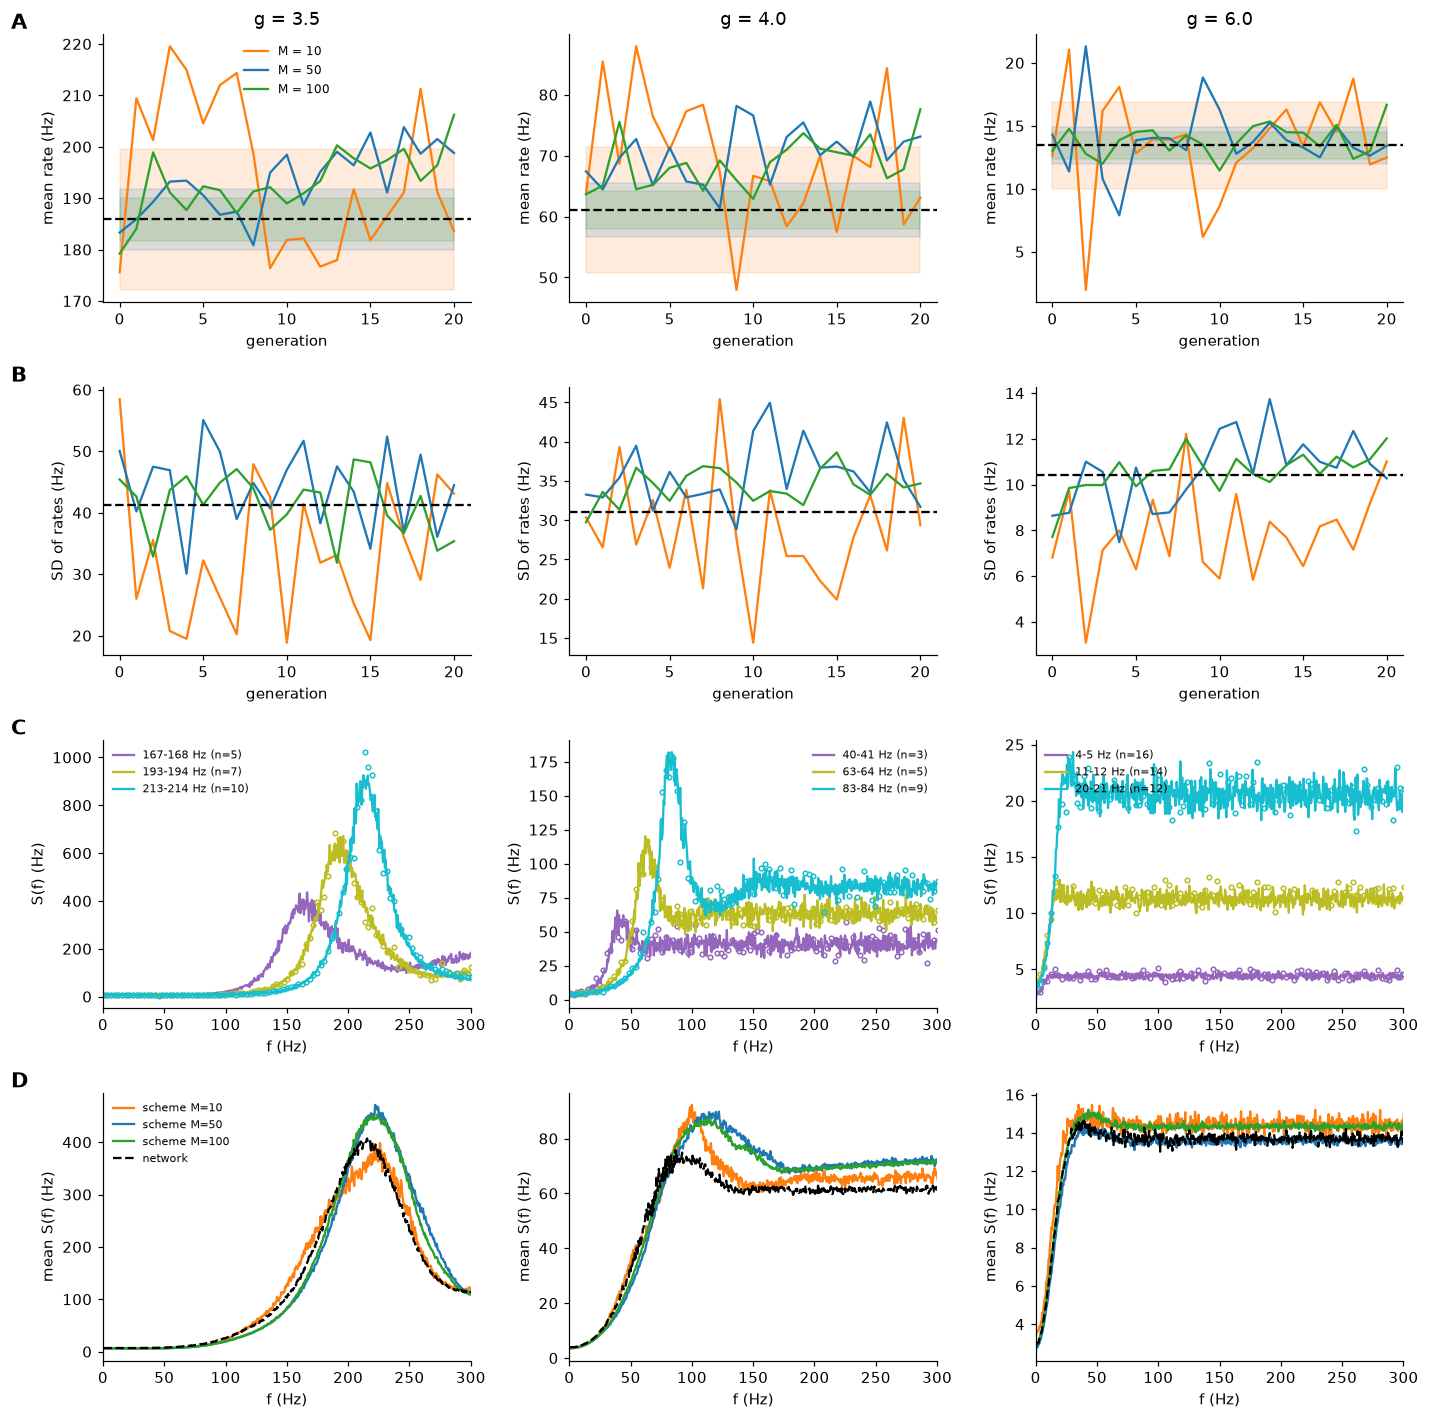

saved figure10_er_fixed.csv (45059 data points)


PosixPath('/workspaces/SC_Cortex/05_Pena2018_Replication/figures/figure10_er_fixed.csv')

In [4]:
fig, axes = plt.subplots(4, len(G_VALUES), figsize=(13, 13))
cols = {10: "tab:orange", 50: "tab:blue", 100: "tab:green"}
for c, g in enumerate(G_VALUES):
    n = net[WEIGHTS, g]; rn = n["rates"][: int(n["offsets"][1])]
    mu_n, sd_n = rn.mean(), rn.std()
    gens = np.arange(21)
    for M in M_VALUES:
        r = sch[WEIGHTS, g, M]["rates"]
        axes[0, c].plot(gens, r.mean(1), "-", color=cols[M], label=f"M = {M}")
        axes[0, c].fill_between(gens, mu_n - sd_n / np.sqrt(M - 1), mu_n + sd_n / np.sqrt(M - 1), color=cols[M], alpha=0.15)
        axes[1, c].plot(gens, r.std(1), "-", color=cols[M])
    axes[0, c].axhline(mu_n, ls="--", color="k"); axes[1, c].axhline(sd_n, ls="--", color="k")
    axes[0, c].set(title=f"g = {g}", xlabel="generation", ylabel="mean rate (Hz)")
    axes[1, c].set(xlabel="generation", ylabel="SD of rates (Hz)")
    # C: rate-binned spectra
    s = sch[WEIGHTS, g, 50]; g0, g1 = GEN_C[g]
    rs = s["rates"][g0:g1].ravel(); Ss = s["spectra"][g0:g1].reshape(-1, s["spectra"].shape[-1])
    f = s["f"]
    for q, col in zip([25, 50, 75], ["tab:purple", "tab:olive", "tab:cyan"]):
        center = np.percentile(rn, q); lo, hi = np.floor(center), np.floor(center) + 1
        ms_ = (rs >= lo) & (rs < hi); mn_ = (n["rec_rates"] >= lo) & (n["rec_rates"] < hi)
        if ms_.any(): axes[2, c].plot(f[1:], Ss[ms_].mean(0)[1:], "-", color=col, label=f"{lo:.0f}-{hi:.0f} Hz (n={ms_.sum()})")
        if mn_.any(): axes[2, c].plot(f[1::6], n["rec_S"][mn_].mean(0)[1::6], "o", ms=3, mfc="none", color=col)
    axes[2, c].set(xlim=(0, 300), xlabel="f (Hz)", ylabel="S(f) (Hz)"); axes[2, c].legend(frameon=False, fontsize=7)
    # D: population average
    for M in M_VALUES:
        sM = sch[WEIGHTS, g, M]
        axes[3, c].plot(f[1:], sM["spectra"][11:21].mean((0, 1))[1:], "-", color=cols[M], label=f"scheme M={M}")
    axes[3, c].plot(f[1:], n["rec_S"].mean(0)[1:], "--", color="k", label="network")
    axes[3, c].set(xlim=(0, 300), xlabel="f (Hz)", ylabel="mean S(f) (Hz)")
axes[0, 0].legend(frameon=False, fontsize=8); axes[3, 0].legend(frameon=False, fontsize=7)
for r, lab in enumerate("ABCD"): axes[r, 0].annotate(lab, (-0.25, 1.02), xycoords="axes fraction", fontsize=14, weight="bold")
fig.tight_layout(); fig.savefig(FIGURES / f"figure10_er_{WEIGHTS}.png", dpi=200); plt.show()
import pena_export; pena_export.figure_csv(fig, FIGURES / f"figure10_er_{WEIGHTS}.csv")

In [5]:
for g in G_VALUES:
    n = net[WEIGHTS, g]; rn = n["rates"][: int(n["offsets"][1])]
    f = n["f"]
    for M in M_VALUES:
        s = sch[WEIGHTS, g, M]
        Ssch = s["spectra"][11:21].mean((0, 1)); Snet = n["rec_S"].mean(0)
        e = ps.relative_error(f, Snet, Ssch, 2 * rn.mean())
        print(f"g={g} M={M:3d}: mean {s['rates'][6:].mean():6.2f}/{rn.mean():6.2f} Hz, "
              f"SD {s['rates'][6:].std(1).mean():6.2f}/{rn.std():6.2f} Hz, Eq.19 error of mean spectrum {e:.3f}")

g=3.5 M= 10: mean 190.48/185.89 Hz, SD  33.72/ 41.19 Hz, Eq.19 error of mean spectrum 0.008
g=3.5 M= 50: mean 194.95/185.89 Hz, SD  43.70/ 41.19 Hz, Eq.19 error of mean spectrum 0.045
g=3.5 M=100: mean 194.81/185.89 Hz, SD  41.11/ 41.19 Hz, Eq.19 error of mean spectrum 0.030
g=4.0 M= 10: mean  66.37/ 61.06 Hz, SD  28.60/ 30.98 Hz, Eq.19 error of mean spectrum 0.020
g=4.0 M= 50: mean  71.10/ 61.06 Hz, SD  36.21/ 30.98 Hz, Eq.19 error of mean spectrum 0.036
g=4.0 M=100: mean  69.43/ 61.06 Hz, SD  34.87/ 30.98 Hz, Eq.19 error of mean spectrum 0.028
g=6.0 M= 10: mean  13.42/ 13.45 Hz, SD   8.19/ 10.43 Hz, Eq.19 error of mean spectrum 0.018
g=6.0 M= 50: mean  14.12/ 13.45 Hz, SD  11.02/ 10.43 Hz, Eq.19 error of mean spectrum 0.005
g=6.0 M=100: mean  14.01/ 13.45 Hz, SD  10.88/ 10.43 Hz, Eq.19 error of mean spectrum 0.000


## Notes

_Filled in after the run._